# Phase 5: Segments and verdict
**Question:** who does the effect actually hit?

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt

df = pd.read_csv('cookie_cats.csv')

In [2]:
q1, q2, q3 = df['sum_gamerounds'].quantile([0.25, 0.5, 0.75])
def tier(x):
    if x <= q1: return 'Q1 (low engagement)'
    elif x <= q2: return 'Q2'
    elif x <= q3: return 'Q3'
    return 'Q4 (high engagement)'
df['engagement_tier'] = df['sum_gamerounds'].apply(tier)
print(f"Quartile cutoffs on sum_gamerounds: Q1<={q1}, Q2<={q2}, Q3<={q3}")
print(df['engagement_tier'].value_counts().sort_index())

Quartile cutoffs on sum_gamerounds: Q1<=5.0, Q2<=16.0, Q3<=51.0
engagement_tier
Q1 (low engagement)     24717
Q2                      20397
Q3                      22622
Q4 (high engagement)    22453
Name: count, dtype: int64


In [3]:
metric = 'retention_7'
tiers = ['Q1 (low engagement)', 'Q2', 'Q3', 'Q4 (high engagement)']
rows = []
for t in tiers:
    sub = df[df['engagement_tier'] == t]
    g30 = sub[sub['version'] == 'gate_30'][metric].astype(int)
    g40 = sub[sub['version'] == 'gate_40'][metric].astype(int)
    nobs = np.array([len(g30), len(g40)])
    p_pool = (g30.sum() + g40.sum()) / nobs.sum()
    se = np.sqrt(p_pool * (1 - p_pool) * (1/nobs[0] + 1/nobs[1]))
    z = (g30.mean() - g40.mean()) / se
    rows.append(dict(tier=t, n30=nobs[0], n40=nobs[1], control=g30.mean(), treatment=g40.mean(),
                     gap_pp=(g30.mean() - g40.mean()) * 100, raw_p=2 * (1 - stats.norm.cdf(abs(z)))))

res = pd.DataFrame(rows)
reject, p_adj, _, _ = multipletests(res['raw_p'], alpha=0.05, method='fdr_bh')
res['bh_adj_p'] = p_adj
res['significant'] = reject
res.round({'control': 4, 'treatment': 4, 'gap_pp': 2, 'raw_p': 4, 'bh_adj_p': 4})

,tier,n30,n40,control,treatment,gap_pp,raw_p,bh_adj_p,significant
0,Q1 (low engagement),12056,12661,0.0122,0.0131,-0.09,0.5188,0.6917,False
1,Q2,10113,10284,0.0417,0.0409,0.08,0.7766,0.7766,False
2,Q3,11562,11060,0.1477,0.1322,1.55,0.0008,0.0015,True
3,Q4 (high engagement),10969,11484,0.5675,0.5425,2.50,0.0002,0.0007,True


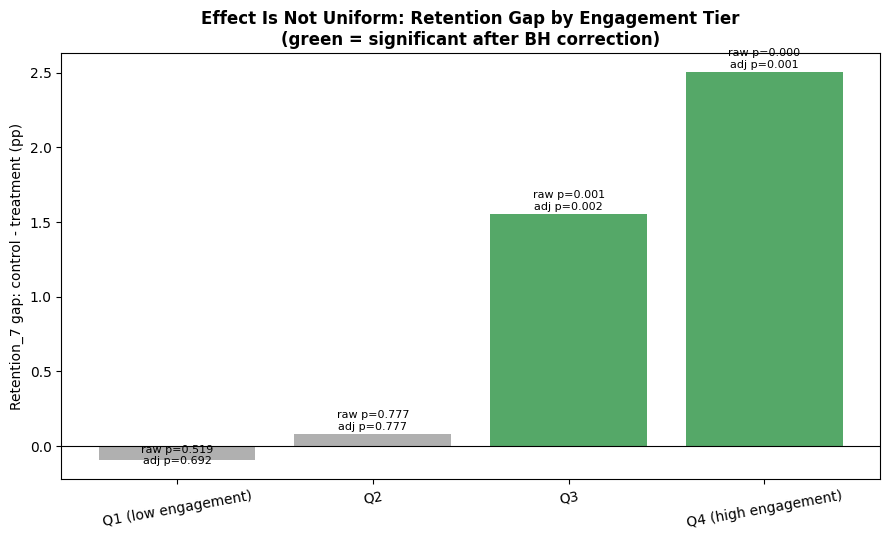

In [4]:
fig, ax = plt.subplots(figsize=(9, 5.5))
colors = ['#55A868' if s else '#B0B0B0' for s in res['significant']]
bars = ax.bar(res['tier'], res['gap_pp'], color=colors)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('Retention_7 gap: control - treatment (pp)')
ax.set_title('Effect Is Not Uniform: Retention Gap by Engagement Tier\n(green = significant after BH correction)',
             fontsize=12, fontweight='bold')
for b, (_, r) in zip(bars, res.iterrows()):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.03 * np.sign(b.get_height() + 0.01),
            f"raw p={r['raw_p']:.3f}\nadj p={r['bh_adj_p']:.3f}", ha='center', fontsize=8)
plt.xticks(rotation=10)
plt.tight_layout()
plt.savefig('chart3_segment_effects.png', dpi=150, bbox_inches='tight')
plt.show()